# 03 · First results (midterm)

**Project:** AI Music Generation Validator · **Data:** SunoCaps (256 Suno tracks = 64 prompts × 4 versions)

This notebook only *reads* the outputs of the pipeline — `data/processed/` (scripts 1–4) and `results/`.
No model is run here. To rebuild everything:

```
python scripts/extract_audio_features.py   # audio -> tempo + CLAP embeddings (cached)
python scripts/build_ground_truth.py       # expert comments -> ground truth
python scripts/parse_prompts.py            # prompts -> requirements
python scripts/run_validation.py           # verdicts, baselines, metrics -> results/
```

All confidence intervals are 95% cluster-bootstrap intervals over `original_id` (1000 resamples):
the 4 versions of a prompt share the prompt and often the expert comment, so they are not independent.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().resolve().parent
PROC, RES = ROOT / "data" / "processed", ROOT / "results"
FIG = RES / "figures"
CATEGORIES = ["genre", "instruments", "vocals", "tempo", "mood", "other"]
pd.set_option("display.max_colwidth", 110)
pd.set_option("display.width", 200)

gt_track = pd.read_csv(PROC / "ground_truth_per_track.csv")
gt_cat = pd.read_csv(PROC / "ground_truth_per_category.csv")
records = pd.read_csv(PROC / "mismatch_records.csv")
reqs = pd.read_csv(PROC / "requirements.csv")
verdicts = pd.read_csv(PROC / "requirement_verdicts.csv")
preds = pd.read_csv(PROC / "predictions_per_category.csv")


def ci(row, key, digits=2):
    """'0.62 [0.51, 0.71]' from a metrics row with key, key_lo, key_hi."""
    v, lo, hi = row[key], row.get(f"{key}_lo", np.nan), row.get(f"{key}_hi", np.nan)
    if pd.isna(v):
        return "–"
    return f"{v:.{digits}f} [{lo:.{digits}f}, {hi:.{digits}f}]" if pd.notna(lo) else f"{v:.{digits}f}"

## 1. Data & ground truth

In [2]:
commented = gt_track[gt_track["has_comment"]]
pending = records["review_status"].isin(["needs_review", "needs_audio_review"]).sum()
print(f"{len(gt_track)} tracks = {gt_track['original_id'].nunique()} prompts x 4 versions "
      f"(_1/_2 aspect list, _3/_4 caption); {len(commented)} tracks have an expert comment")
print(f"{len(records)} expert mismatch records, {pending} of them still need review")
commented["comment_type"].value_counts().rename("commented tracks").to_frame()

256 tracks = 64 prompts x 4 versions (_1/_2 aspect list, _3/_4 caption); 183 tracks have an expert comment
213 expert mismatch records, 62 of them still need review


,commented tracks
comment_type,
mismatch,160
mixed,10
positive,8
descriptive,5


**Expert mismatch rate per category × prompt type** (commented tracks, share of tracks with ≥ 1 mismatch in that category):

In [3]:
a = gt_cat[gt_cat["gt_source"] != "no_comment_assumed_ok"]
rate = a.pivot_table(index="category", columns="prompt_type", values="gt_mismatch", aggfunc="mean").reindex(CATEGORIES)
rate["expert positives"] = a.groupby("category")["gt_mismatch"].sum()
rate.round(3)

prompt_type,aspect_list,caption,expert positives
category,,,
genre,0.132,0.087,20
instruments,0.176,0.239,38
vocals,0.363,0.402,70
tempo,0.000,0.000,0
mood,0.000,0.000,0
other,0.440,0.370,74


**What kind of mismatch the experts report** (from the 213 mismatch records):

In [4]:
kinds = pd.crosstab(records["category"], records["verdict"]).reindex(index=CATEGORIES, fill_value=0)
kinds = kinds.reindex(columns=["ignored", "changed", "hallucinated"], fill_value=0)
kinds["records"] = kinds.sum(axis=1)
shares = kinds[["ignored", "changed", "hallucinated"]].div(kinds["records"].replace(0, np.nan), axis=0)
pd.concat([kinds, shares.add_prefix("share ").round(2)], axis=1)

verdict,ignored,changed,hallucinated,records,share ignored,share changed,share hallucinated
category,,,,,,,
genre,0,20,0,20,0.00,1.00,0.00
instruments,33,2,3,38,0.87,0.05,0.08
vocals,37,25,10,72,0.51,0.35,0.14
tempo,0,0,0,0,NaN,NaN,NaN
mood,0,0,0,0,NaN,NaN,NaN
other,27,56,0,83,0.33,0.67,0.00


**Tempo and mood have no expert labels at all** (0 records): the experts never commented on them, so
these two categories cannot be evaluated against the experts — only by our own listening (planned).

## 2. Prompt parsing (rule-based)

In [5]:
first = gt_track.drop_duplicates(["original_id", "prompt_type"])  # one track per distinct prompt
n_req = reqs.groupby("track_id").size()
per_prompt = first.assign(n_requirements=first["track_id"].map(n_req).fillna(0))
print(f"{len(reqs)} requirements for {reqs['track_id'].nunique()} tracks; per distinct prompt:")
per_prompt.groupby("prompt_type")["n_requirements"].agg(["mean", "min", "max"]).round(1)

2172 requirements for 256 tracks; per distinct prompt:


,mean,min,max
prompt_type,,,
aspect_list,10.5,5,19
caption,6.5,1,13


In [6]:
u = reqs[reqs["track_id"].isin(first["track_id"])]
pd.crosstab(u["category"], u["prompt_type"]).reindex(CATEGORIES)

prompt_type,aspect_list,caption
category,,
genre,74,43
instruments,197,166
vocals,90,84
tempo,28,16
mood,129,67
other,151,41


**Coverage vs the expert records** (unexpected additions skipped): does the parser produce a requirement of
the record's category (*category level*), and one that names the expert's element (*element level*, simple
word matching)?

In [7]:
pd.read_csv(RES / "prompt_coverage.csv").set_index("category")

,records,category_level,element_level
category,,,
genre,20,90.0,70.0
instruments,35,94.3,94.3
other,80,97.5,92.5
vocals,62,96.8,96.8
all,197,95.9,91.9


All remaining element-level misses (16 records) are cases where the prompt itself does not name the element
(e.g. the expert says "not *Indian classical*", the prompt says "hindi") — 0 parser misses. Three records
(composition, rhythmic figure) cannot come from prompt words at all and are not counted.

## 3. Results

### 3.1 Per category (main result: commented tracks, subset A)

Each cell is one (track, category). The model predicts a mismatch if any requirement of that category is
`ignored` / `changed` / `hallucinated`; ROC-AUC uses the strongest mismatch score. *Trivial baseline* =
predict a mismatch whenever the prompt has a requirement in that category.

In [8]:
m = pd.read_csv(RES / "metrics_per_category.csv")
a = m[m["subset"] == "A_commented"]
mod = a[a["system"] == "modular"].set_index("category")
triv = a[a["system"] == "trivial"].set_index("category")
pd.DataFrame({
    "positives": mod["support"],
    "precision": [ci(r, "precision") for _, r in mod.iterrows()],
    "recall": [ci(r, "recall") for _, r in mod.iterrows()],
    "F1": [ci(r, "f1") for _, r in mod.iterrows()],
    "ROC-AUC": [ci(r, "roc_auc") for _, r in mod.iterrows()],
    "trivial F1": [ci(r, "f1") for _, r in triv.iterrows()],
    "note": mod["note"],
})

,positives,precision,recall,F1,ROC-AUC,trivial F1,note
category,,,,,,,
genre,20,"0.29 [0.05, 0.56]","0.35 [0.08, 0.67]","0.32 [0.06, 0.53]","0.74 [0.59, 0.88]","0.27 [0.08, 0.43]",NaN
instruments,38,"0.26 [0.13, 0.41]","0.58 [0.35, 0.81]","0.36 [0.20, 0.51]","0.55 [0.38, 0.71]","0.35 [0.19, 0.48]",NaN
vocals,70,"0.64 [0.48, 0.80]","0.90 [0.80, 0.98]","0.75 [0.62, 0.85]","0.84 [0.75, 0.91]","0.55 [0.40, 0.68]",NaN
tempo,0,"0.00 [0.00, 0.00]",–,"0.00 [0.00, 0.00]",–,"0.00 [0.00, 0.00]",not enough labels
mood,0,"0.00 [0.00, 0.00]",–,"0.00 [0.00, 0.00]",–,"0.00 [0.00, 0.00]",not enough labels
other,74,"0.62 [0.45, 0.77]","0.65 [0.52, 0.79]","0.64 [0.50, 0.75]","0.76 [0.66, 0.85]","0.70 [0.57, 0.81]",NaN
micro,202,"0.49 [0.42, 0.57]","0.69 [0.60, 0.79]","0.58 [0.50, 0.65]","0.76 [0.70, 0.82]","0.48 [0.44, 0.53]",NaN
macro,202,"0.45 [0.37, 0.54]","0.62 [0.51, 0.74]","0.52 [0.43, 0.60]","0.72 [0.65, 0.80]","0.47 [0.41, 0.52]",NaN


Tempo and mood rows are not an evaluation: without expert labels every model flag counts as a false positive.
Micro / macro use the four labelled categories. The same averages on the other ground-truth subsets
(A-reviewed = without cells that still need review; B = all 256 tracks, no comment = OK):

In [9]:
avg = m[m["category"].isin(["micro", "macro"])]
pd.DataFrame({"subset": avg["subset"], "system": avg["system"], "average": avg["category"],
              "F1": [ci(r, "f1") for _, r in avg.iterrows()],
              "ROC-AUC": [ci(r, "roc_auc") for _, r in avg.iterrows()]}).reset_index(drop=True)

,subset,system,average,F1,ROC-AUC
0,A_commented,modular,micro,"0.58 [0.50, 0.65]","0.76 [0.70, 0.82]"
1,A_commented,modular,macro,"0.52 [0.43, 0.60]","0.72 [0.65, 0.80]"
2,A_commented,trivial,micro,"0.48 [0.44, 0.53]","0.63 [0.56, 0.70]"
3,A_commented,trivial,macro,"0.47 [0.41, 0.52]","0.62 [0.55, 0.69]"
4,A_reviewed,modular,micro,"0.54 [0.45, 0.62]","0.73 [0.66, 0.80]"
5,A_reviewed,modular,macro,"0.53 [0.43, 0.61]","0.73 [0.64, 0.82]"
6,A_reviewed,trivial,micro,"0.48 [0.42, 0.55]","0.61 [0.52, 0.69]"
7,A_reviewed,trivial,macro,"0.49 [0.43, 0.55]","0.63 [0.55, 0.71]"
8,B_all,modular,micro,"0.50 [0.43, 0.56]","0.76 [0.70, 0.81]"
9,B_all,modular,macro,"0.46 [0.37, 0.52]","0.72 [0.66, 0.79]"


### 3.2 Track level: does the track have any mismatch?

Modular system (max mismatch score) vs **CLAP global similarity** (cosine between the track and the full
prompt) vs the trivial baseline (number of categories the prompt mentions). F1 uses a threshold chosen on
the other folds (5-fold GroupKFold over `original_id`). On subset A only 13 of 183 tracks have no mismatch,
so subset B is the informative one.

In [10]:
t = pd.read_csv(RES / "metrics_track_level.csv")
pd.DataFrame({"subset": t["subset"], "system": t["system"], "positives": t["support"].astype(str) + "/" + t["n"].astype(str),
              "ROC-AUC": [ci(r, "roc_auc") for _, r in t.iterrows()],
              "F1": [ci(r, "f1") for _, r in t.iterrows()]})

,subset,system,positives,ROC-AUC,F1
0,A_commented,modular system,170/183,"0.65 [0.50, 0.83]","0.95 [0.91, 0.99]"
1,A_commented,CLAP global similarity,170/183,"0.53 [0.25, 0.90]","0.96 [0.92, 0.99]"
2,A_commented,trivial (n categories with a requirement),170/183,"0.51 [0.27, 0.78]","0.96 [0.92, 0.99]"
3,A_commented,modular (own rule: any category flagged),170/183,"0.65 [0.50, 0.83]","0.93 [0.89, 0.97]"
4,B_all,modular system,170/256,"0.64 [0.54, 0.74]","0.80 [0.73, 0.85]"
5,B_all,CLAP global similarity,170/256,"0.58 [0.46, 0.69]","0.80 [0.72, 0.86]"
6,B_all,trivial (n categories with a requirement),170/256,"0.49 [0.39, 0.59]","0.79 [0.71, 0.86]"
7,B_all,modular (own rule: any category flagged),170/256,"0.64 [0.54, 0.74]","0.80 [0.73, 0.86]"


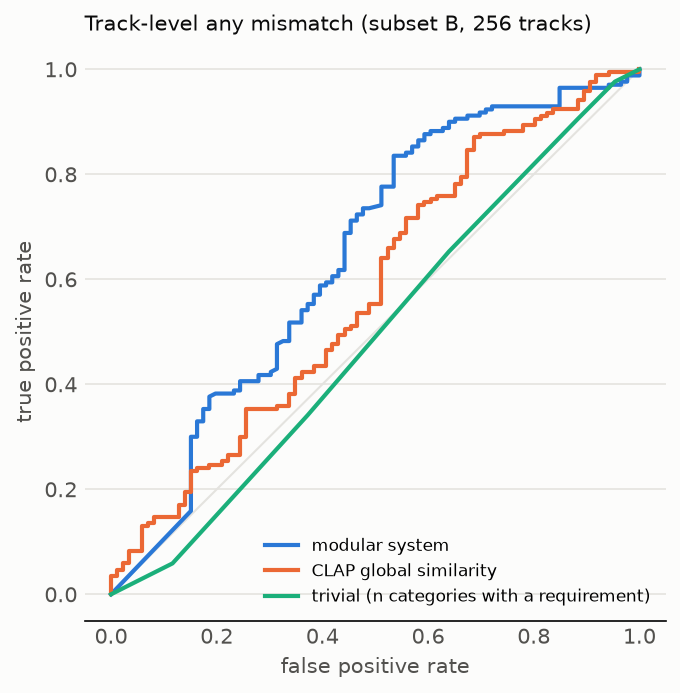

In [11]:
display(Image(filename=FIG / "track_level_roc.png", width=420))

### 3.3 tau for the CLAP checks

A CLAP check is *satisfied* if the track's similarity is at least at percentile tau among tracks whose prompt
does not mention that element. Default tau = 0.5; GroupKFold over `original_id` picks:

In [12]:
cv = pd.read_csv(RES / "metrics_tau_cv.csv")
print("tau chosen per fold:", cv["chosen_taus"].iloc[0])
pd.DataFrame({"F1, tau = 0.5": [ci(r, "f1") for _, r in mod.loc[["genre", "instruments", "vocals", "other", "micro"]].iterrows()],
              "F1, tau by GroupKFold": [ci(r, "f1") for _, r in cv.set_index("category").loc[["genre", "instruments", "vocals", "other", "micro"]].iterrows()]},
             index=["genre", "instruments", "vocals", "other", "micro"])

tau chosen per fold: 0.55, 0.55, 0.55, 0.55, 0.55


,"F1, tau = 0.5","F1, tau by GroupKFold"
genre,"0.32 [0.06, 0.53]","0.37 [0.07, 0.60]"
instruments,"0.36 [0.20, 0.51]","0.36 [0.21, 0.50]"
vocals,"0.75 [0.62, 0.85]","0.75 [0.62, 0.85]"
other,"0.64 [0.50, 0.75]","0.67 [0.53, 0.78]"
micro,"0.58 [0.50, 0.65]","0.59 [0.51, 0.65]"


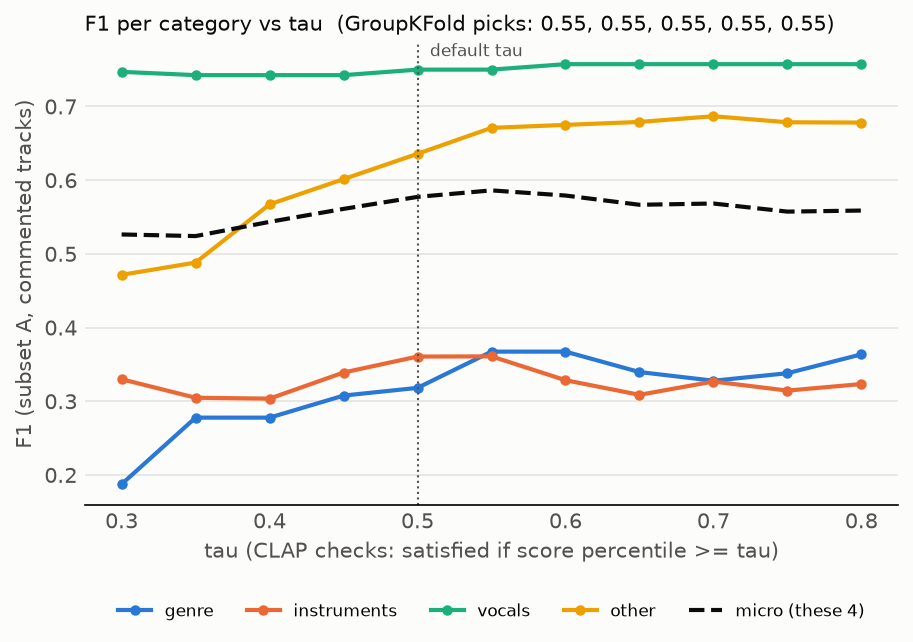

In [13]:
display(Image(filename=FIG / "tau_sweep.png", width=600))

### 3.4 Vocal presence

CLAP zero-shot *"a song with singing vocals"* vs *"instrumental music without vocals"* against
`vocals_present_gt`, which comes from the expert comment when it says so, otherwise from the `Instrumental`
column (the generator setting — a weak label).

In [14]:
vo = pd.read_csv(RES / "metrics_vocals.csv")
pd.DataFrame({"label source": vo["label_source"], "tracks": vo["n"],
              "accuracy": [ci(r, "accuracy") for _, r in vo.iterrows()],
              "macro-F1": [ci(r, "macro_f1") for _, r in vo.iterrows()]})

,label source,tracks,accuracy,macro-F1
0,comment,45,"0.78 [0.64, 0.91]","0.62 [0.42, 0.82]"
1,instrumental_flag,211,"0.83 [0.75, 0.90]","0.81 [0.72, 0.89]"
2,all,256,"0.82 [0.75, 0.88]","0.80 [0.70, 0.87]"


### 3.5 Emotion (8 SunoCaps emotions, zero-shot `"{emotion} music"`)

In [15]:
em = pd.read_csv(RES / "metrics_emotion.csv")
pd.DataFrame({"method": em["method"], "accuracy": [ci(r, "accuracy") for _, r in em.iterrows()],
              "macro-F1": [ci(r, "macro_f1") for _, r in em.iterrows()]})

,method,accuracy,macro-F1
0,CLAP zero-shot,"0.32 [0.23, 0.40]","0.23 [0.16, 0.28]"
1,CLAP zero-shot + prior correction,"0.29 [0.22, 0.36]","0.22 [0.17, 0.27]"
2,majority class (happy),"0.36 [0.26, 0.45]","0.07 [0.05, 0.08]"


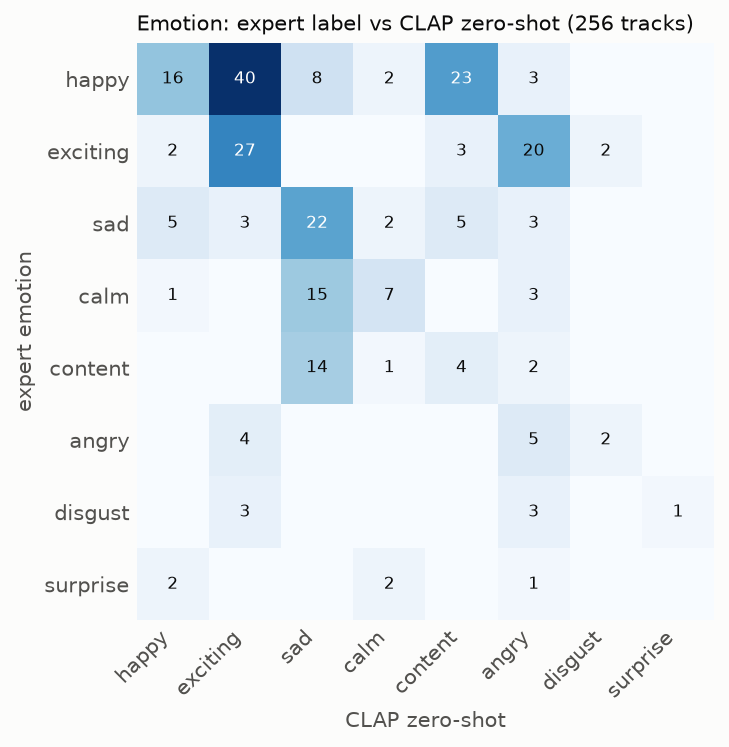

In [16]:
display(Image(filename=FIG / "emotion_confusion.png", width=420))

CLAP is below the majority class in accuracy but far above it in macro-F1: it confuses neighbouring emotions (happy / exciting / content, calm / sad).

### 3.6 Tempo: which estimator separates "fast" from "slow" prompts?

88 tracks whose prompt has a tempo word; ROC-AUC for fast- vs slow-prompted tracks (0.5 = random).

In [17]:
tc = pd.read_csv(RES / "tempo_comparison_summary.csv")
tc[["estimator", "median_fast", "median_slow", "auc_fast_vs_slow"]].round(3)

,estimator,median_fast,median_slow,auc_fast_vs_slow
0,a) librosa beat tracker,117.454,126.123,0.466
1,"b) librosa, flat prior",126.123,86.133,0.691
2,c) CLAP argmax,0.188,-0.856,0.899
3,d) CLAP prior-corrected,0.410,-0.705,0.899


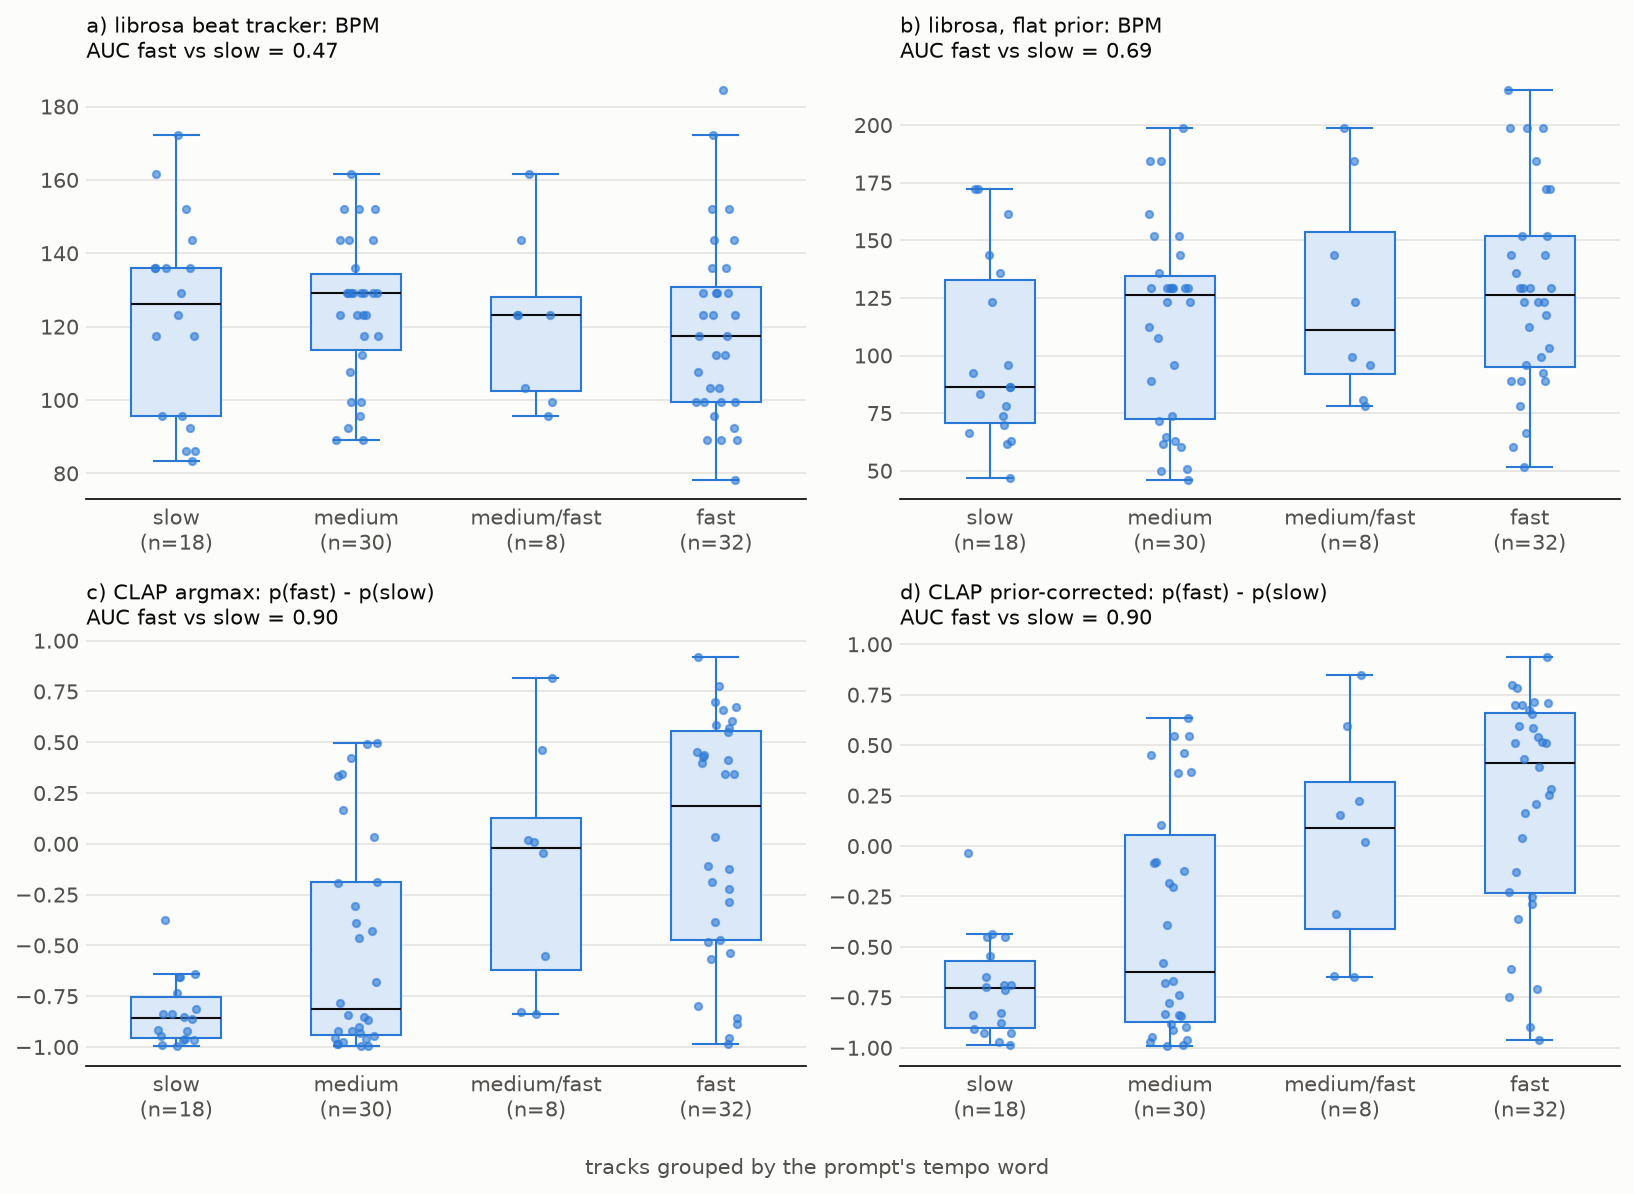

In [18]:
display(Image(filename=FIG / "tempo_comparison.png", width=700))

The librosa beat tracker is pulled towards ~120 BPM (slow songs come out at double tempo), so tempo words
are checked with CLAP + prior correction. A 24-track listening check (`results/tempo_listening.csv`) is still
to be labelled.

## 4. Aspect list vs caption

Share of *satisfied* requirements per track (rates, not counts: aspect prompts have ~10.5 requirements,
captions ~6.5), averaged per prompt type and compared **within** each `original_id` (paired).

In [19]:
pt = pd.read_csv(RES / "metrics_prompt_type.csv")
pd.DataFrame({"measure": pt["measure"], "pairs": pt["n_pairs"], "aspect list": pt["aspect_list"].round(3),
              "caption": pt["caption"].round(3), "difference": [ci(r, "diff", 3) for _, r in pt.iterrows()],
              "Wilcoxon p": pt["wilcoxon_p"].round(3)})

,measure,pairs,aspect list,caption,difference,Wilcoxon p
0,model: share of satisfied requirements (all categories),64,0.697,0.692,"0.004 [-0.058, 0.067]",0.803
1,model: share of satisfied requirements (genre),33,0.871,0.879,"-0.008 [-0.152, 0.129]",1.000
2,model: share of satisfied requirements (instruments),59,0.712,0.698,"0.014 [-0.091, 0.121]",0.912
3,model: share of satisfied requirements (vocals),44,0.690,0.656,"0.034 [-0.064, 0.133]",0.498
4,model: share of satisfied requirements (tempo),13,0.654,0.577,"0.077 [-0.192, 0.385]",0.766
5,model: share of satisfied requirements (mood),30,0.753,0.695,"0.058 [-0.047, 0.168]",0.365
6,model: share of satisfied requirements (other),28,0.610,0.675,"-0.065 [-0.193, 0.071]",0.351
7,experts: share of tracks with a mismatch (no comment = OK),64,0.664,0.664,"0.000 [-0.094, 0.086]",0.914


No difference between the two prompt types, neither by the model nor by the experts.

## 5. Five example tracks

For each track: the prompt, the expert comment, our requirement-level verdicts (`prob` = CLAP probability for
vocal checks, `score_pct` = similarity percentile for CLAP checks) and the per-category comparison with the
expert ground truth.

In [20]:
tracks = gt_track.set_index("track_id")


def show(track_id):
    print("PROMPT: ", tracks.loc[track_id, "actual_prompt"])
    print("EXPERT: ", tracks.loc[track_id, "expert_comment"])
    v = verdicts[verdicts["track_id"] == track_id]
    display(v[["category", "value", "polarity", "check", "verdict", "prob", "score_pct"]].round(2).reset_index(drop=True))
    p = preds[preds["track_id"] == track_id].set_index("category").loc[CATEGORIES]
    display(p[["n_requirements", "pred_mismatch", "gt_mismatch"]].T)

**Example 1 — good (`2ShO1jZYZeA_1`).**

In [21]:
show("2ShO1jZYZeA_1")

PROMPT:  techno song, synth sounds, programmed percussion, fast tempo, no voices, instrumental, adverticement music
EXPERT:  Not instrumental


,category,value,polarity,check,verdict,prob,score_pct
0,genre,techno,1,essentia_genre,satisfied,NaN,0.98
1,instruments,synth,1,essentia_instrument,satisfied,NaN,0.81
2,instruments,percussion,1,essentia_instrument,satisfied,NaN,0.62
3,tempo,fast,1,tempo,satisfied,NaN,NaN
4,vocals,vocals,-1,vocal_presence,ignored,0.95,NaN
5,genre,advertisement music,1,clap,ignored,NaN,0.20


category,genre,instruments,vocals,tempo,mood,other
n_requirements,2,2,1,1,0,0
pred_mismatch,True,False,True,False,False,False
gt_mismatch,0,0,1,0,0,0


The prompt asks for an instrumental, CLAP hears vocals (p = 0.95) → `ignored`, which is exactly the expert's
"Not instrumental". (The extra genre flag for "advertisement music" is a false positive.)

**Example 2 — good (`2Ic1zm9mBjk_3`).**

In [22]:
show("2Ic1zm9mBjk_3")

PROMPT:  The song is an instrumental. The song is medium tempo with a sitar playing solo, tabla playing percussively and other Indian percussion instruments. The song is emotional and poignant. 
EXPERT:  Not classical hindustani music. Better that the other versions. follows the instrumental prompt without specialy selecting the characteristic in the generator.


,category,value,polarity,check,verdict,prob,score_pct
0,vocals,vocals,-1,vocal_presence,satisfied,0.0,NaN
1,tempo,medium,1,tempo,satisfied,NaN,NaN
2,instruments,sitar,1,clap,satisfied,NaN,0.99
3,instruments,tabla,1,clap,satisfied,NaN,0.81
4,instruments,percussion,1,essentia_instrument,satisfied,NaN,0.79
5,genre,indian,1,essentia_genre,ignored,NaN,0.21
6,mood,emotional,1,essentia_mood,satisfied,NaN,0.95
7,mood,poignant,1,clap,satisfied,NaN,0.96


category,genre,instruments,vocals,tempo,mood,other
n_requirements,1,3,1,1,2,0
pred_mismatch,True,False,False,False,False,False
gt_mismatch,1,0,0,0,0,0


No vocals, sitar and tabla are confirmed; the only flag is the genre "indian" (21st percentile) — the same
category the expert criticises ("Not classical hindustani music").

**Example 3 — failure: missed mismatch (`-0Gj8-vB1q4_3`).**

In [23]:
show("-0Gj8-vB1q4_3")

PROMPT:  The low quality recording features a ballad song that contains sustained strings, mellow piano melody and soft female vocal singing over it. It sounds sad and soulful.
EXPERT:  No strings


,category,value,polarity,check,verdict,prob,score_pct
0,vocals,vocals,1,vocal_presence,satisfied,0.87,NaN
1,vocals,female vocals,1,vocal_gender,satisfied,0.99,NaN
2,instruments,strings,1,essentia_instrument,satisfied,NaN,0.94
3,instruments,piano,1,essentia_instrument,satisfied,NaN,0.98
4,genre,ballad,1,essentia_genre,satisfied,NaN,0.96
5,mood,mellow,1,essentia_mood,satisfied,NaN,0.99
6,mood,soft,1,essentia_mood,satisfied,NaN,0.95
7,other,low quality,1,clap,satisfied,NaN,0.97
8,mood,sad,1,essentia_mood,satisfied,NaN,0.98
9,mood,soulful,1,clap,satisfied,NaN,0.97


category,genre,instruments,vocals,tempo,mood,other
n_requirements,1,2,2,0,4,1
pred_mismatch,False,False,False,False,False,False
gt_mismatch,0,1,0,0,0,0


The expert hears no strings, but "music with strings" is at the 94th percentile for this ballad: CLAP rates the
overall sound and cannot confirm that one instrument is missing from the mix.

**Example 4 — failure: false alarm (`-r7iz-9v9bA_3`).**

In [24]:
show("-r7iz-9v9bA_3")

PROMPT:  This song features a female voice singing in opera style using only vocables and no words. This is accompanied by violins playing eighth note patterns that change according to the chords being played. 
EXPERT:  Follows very well the no-lyrics only vocables prompt 


,category,value,polarity,check,verdict,prob,score_pct
0,vocals,lyrics,-1,clap,satisfied,NaN,0.12
1,vocals,vocals,1,vocal_presence,ignored,0.01,NaN
2,vocals,female vocals,1,vocal_gender,not_checked,NaN,NaN
3,vocals,vocables,1,clap,ignored,NaN,0.12
4,genre,opera,1,essentia_genre,satisfied,NaN,0.99
5,instruments,violins,1,essentia_instrument,satisfied,NaN,1.00


category,genre,instruments,vocals,tempo,mood,other
n_requirements,1,1,4,0,0,0
pred_mismatch,False,False,True,False,False,False
gt_mismatch,0,0,0,0,0,0


The expert praises the wordless operatic vocables, but CLAP gives p(vocals) = 0.01: wordless vocables over
violins do not match the text "a song with singing vocals", so the vocal checks fail.

**Example 5 — failure: right on vocals, wrong elsewhere (`-ByoSbgzr4M_1`).**

In [25]:
show("-ByoSbgzr4M_1")

PROMPT:  instrumental, electric guitar, stringed instrument, vibrato, sonic power, amplified guitar, fast tempo, rapid, vigorous, dexterous, skilled, practice, intense, rock, hard rock, home recording
EXPERT:  Does not follow "instrumental" text command.


,category,value,polarity,check,verdict,prob,score_pct
0,vocals,vocals,-1,vocal_presence,ignored,0.87,NaN
1,instruments,electric guitar,1,essentia_instrument,satisfied,NaN,0.82
2,instruments,strings,1,essentia_instrument,ignored,NaN,0.06
3,other,vibrato,1,clap,ignored,NaN,0.14
4,other,sonic power,1,clap,satisfied,NaN,0.83
5,instruments,guitar,1,essentia_instrument,satisfied,NaN,0.64
6,tempo,fast,1,tempo,satisfied,NaN,NaN
7,other,rapid,1,clap,satisfied,NaN,0.67
8,mood,vigorous,1,clap,satisfied,NaN,0.60
9,other,dexterous,1,clap,satisfied,NaN,0.66


category,genre,instruments,vocals,tempo,mood,other
n_requirements,2,3,1,1,2,7
pred_mismatch,False,True,True,False,False,True
gt_mismatch,0,0,1,0,0,0


Vocals in an "instrumental" prompt are caught correctly, but "stringed instrument" (the guitar) was mapped to
orchestral *strings* by a parser alias (a bug found here, to be fixed), and descriptive tags like "vibrato" and
"amateur recording" (from "home recording") are hard for CLAP — three requirement-level false positives that
the experts never mention.

## Takeaways

- The rule-based parser covers 96% of the expert records by category and 92% by element.
- The modular system beats both baselines: micro F1 0.58 vs 0.48 (trivial) on commented tracks; track-level
  ROC-AUC 0.64 vs 0.58 (CLAP global similarity) vs 0.49 (trivial) on all tracks.
- Vocals are the strongest category (F1 0.75, ROC-AUC 0.84); instruments the weakest (ROC-AUC 0.55).
- Tempo words need CLAP (AUC 0.90) rather than the librosa beat tracker (0.47).
- Tempo and mood cannot be evaluated against the experts; our own listening labels are the next step.